In [2]:
import agama, numpy, matplotlib, matplotlib.pyplot as plt
from scipy import optimize 
import hunter2024mwmodel as h2024
import barframe
plt.rcParams.update({
    "font.size": 11,
    "axes.labelsize": 11,
    "axes.titlesize": 11,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "legend.fontsize": 11,
    "text.usetex": True,
    "text.latex.preamble": r"\usepackage{txfonts}",
})
agama.setUnits(length=1, mass=1, velocity=1)

In [3]:
bar1=h2024.coleman2020(**h2024.coleman_components)
bar2=h2024.portail_component(**h2024.portail_bar_1)
bar3=h2024.portail_component(**h2024.portail_bar_2)    
pbar1   = agama.Potential(type='CylSpline', density=bar1,symmetry='triaxial',mmax=8,gridSizeR=40, gridSizeZ=40, Rmin=0.001, Rmax=20, Zmin=0.001, Zmax=20,)
pbar2   = agama.Potential(type='CylSpline', density=bar2,symmetry='triaxial',mmax=8,gridSizeR=40, gridSizeZ=40, Rmin=0.001, Rmax=20, Zmin=0.001, Zmax=20,)
pbar3   = agama.Potential(type='CylSpline', density=bar3,symmetry='triaxial',mmax=8,gridSizeR=40, gridSizeZ=40, Rmin=0.001, Rmax=20, Zmin=0.001, Zmax=20,)
pbar = pbar1+pbar2+pbar3

In [4]:
# the rest of the potetial 
psagA   = agama.Potential(**h2024.supermassiveblackhole)
pnsc    = agama.Potential(**h2024.nsc)
pnsd1   = agama.Potential(**h2024.NSD1,)
pnsd2   = agama.Potential(**h2024.NSD2)
pdisk1  = agama.Potential(**h2024.DISK1)
pdisk2  = agama.Potential(**h2024.DISK2)
pgdisk1 = agama.Potential(**h2024.GDISK1)
pgdisk2 = agama.Potential(**h2024.GDISK2)
phalo   = agama.Potential(**h2024.EINASTO)
pot_total=agama.Potential(pbar1,pbar2,pbar3,psagA,pnsc,pnsd1,pnsd2,pdisk1,pdisk2,pgdisk1,pgdisk2,phalo)

In [5]:
methods=list(dir(pbar))
methodss=[]
for x in methods:
    if x[0]!="_":
        methodss.append(x)
methodss

['Rcirc',
 'Rmax',
 'Rperiapo',
 'Tcirc',
 'density',
 'enclosedMass',
 'eval',
 'export',
 'force',
 'forceDeriv',
 'potential',
 'principalAxes',
 'projectedDensity',
 'projectedEval',
 'sample',
 'totalMass']

- Sample positions randomly within the first lagrange point
- Then, using the jacobii energy, get an isotropic velocity at that point...

In [49]:
omega = -37.5
x_l1, e_l1 = barframe.lagrange_l1_energy(pot_total, omega)
y_l4 = barframe.yL4(pot_total,omega)
e_0  = barframe.pot_eff(pot_total, omega, numpy.array([0.0, 0.0, 0.0]))
e_l4 = barframe.pot_eff(pot_total,omega,numpy.array([0,y_l4,0]))


In [60]:
rng = numpy.random.default_rng(4)
x_sample = rng.uniform(-x_l1, x_l1)
y_max = barframe.ymax_within_bar(pot_total, omega, x_sample, e_l1, x_l1/2)
y_sample = rng.uniform(-y_max, y_max)
z_max = barframe.zmax_within_bar(pot_total, omega, x_sample, y_sample, e_l1, y_max)
z_sample = rng.uniform(-z_max, z_max)
availablespeed = barframe.available_speed(pot_total, omega, [x_sample, y_sample, z_sample], e_l1)
(vx, vy, vz), v_sample, theta, phi = barframe.sample_velocity_isotropic(availablespeed, rng)


aesthetics for the plot 

In [61]:
npoints=201
# get the zero velocity curve in the yz-plane
threshold = 1e-3
y_zvc = numpy.linspace(-(1-threshold)*y_max,(1-threshold)*y_max,npoints)
z_zvc = numpy.array([barframe.zmax_within_bar(pot_total,omega,x_sample,yy,e_l1,y_max) for yy in y_zvc])

# get the countour lines first 
xfactor,yfactor = 4, 1.2
xs,ys=numpy.linspace(-xfactor*x_l1,xfactor*x_l1,npoints),numpy.linspace(-yfactor*x_l1,yfactor*x_l1,npoints)
XS,YS = numpy.meshgrid(xs,ys)
pos=numpy.column_stack((XS.flatten(),YS.flatten(),0*YS.flatten()))
peff = barframe.pot_eff(pot_total,omega,pos)
pot_eff = numpy.reshape(peff,XS.shape)
contours = numpy.linspace(pot_eff.min(),pot_eff.max(),10)
# add teh special contours 
contours=numpy.concatenate((contours,numpy.linspace(e_l1*(1+.4e-3),e_l4,5)))
contours=numpy.sort(contours)


# now visualize sampling the x-position 
pos = numpy.column_stack([xs,xs*0,xs*0])
phi_x = barframe.pot_eff(pot_total,omega,pos)
phi_x_sample = barframe.pot_eff(pot_total,omega,numpy.array([x_sample,0,0]))
phi_0 = barframe.pot_eff(pot_total,omega,numpy.array([0.1,0.1,0.1]))

# now what?
pos = numpy.column_stack((x_sample*numpy.ones_like(ys), ys,0*ys))
phi_y_at_x = barframe.pot_eff(pot_total,omega,pos)
phi_y_max_at_x = barframe.pot_eff(pot_total,omega,numpy.array([x_sample,y_max,0]))
phi_y_max_at_x_sample = barframe.pot_eff(pot_total,omega,numpy.array([x_sample,y_sample,0]))


In [ ]:
figbasename = "plots/bar_init_conds/bar_init_conds_fig_frame_{:03d}.png"
framecounter=0
nrow,ncol=3,2
fig = plt.figure()
gs=matplotlib.gridspec.GridSpec(3,2,figure=fig)
axis=fig.add_subplot(gs[0,:])
axes = []
for i in range(1,nrow):
    axes.append([])
    for j in range(ncol):
        axes[i-1].append(fig.add_subplot(gs[i,j]))
# remove the bottom one because I split it later 
axes[1][1].remove()
contour1=axis.contour(XS,YS,pot_eff,levels=contours,colors="k",linestyle="-");
axis.set(aspect="equal",xlabel="x", ylabel="y",)

# start the axes for the effective potential 
axes[0][0].set(xlabel="x", ylabel=r"$\Phi_{\mathrm{eff}}(x,0,0)$",yticks=[],xlim=[xs.min(),xs.max()],ylim=[phi_0,(1-3e-2)*phi_x.max()]);
### START THE PLOT FOR SAMPLING y 
axes[0][1].set(ylabel=r"$\Phi_{\mathrm{eff}}(x_s,y,0)$",yticks=[],xlabel="y",xlim=[ys.min(),ys.max()],ylim=[phi_y_at_x.min(),(1-1e-2)*phi_y_at_x.max()]);
# the zero velocity curve 
obj,=axes[1][0].plot(numpy.concatenate((y_zvc, y_zvc[::-1],[y_zvc[0]])),numpy.concatenate((z_zvc,-z_zvc[::-1],[z_zvc[0]])),color="k")
axes[1][0].set(xlabel="y", ylabel="z", )
fig.tight_layout()
obj.remove()
contour1.remove()
fig.savefig(figbasename.format(framecounter),dpi=300)
framecounter+=1

### THE EFFECTIVE POTENTIAL 
axis.contour(XS,YS,pot_eff,levels=contours,colors="k",linestyle="-");
axis.set(aspect="equal",xlabel="x", ylabel="y",title=r"Milky-Way $\Phi_{\mathrm{eff}}$ Hunter et al. (2024)")
fig.tight_layout()
fig.savefig(figbasename.format(framecounter),dpi=300)
framecounter+=1

# plot the effective potential at y=0
axes[0][0].plot(xs,phi_x,color="k")
fig.tight_layout()
fig.savefig(figbasename.format(framecounter),dpi=300)
framecounter+=1

# show the box that we'll be inside for picking an x_sample
axes[0][0].hlines(e_l1,-x_l1,x_l1,color="k",linewidth=1)
axes[0][0].vlines([-x_l1, x_l1],e_0,e_l1,color="k",linewidth=1)
fig.tight_layout()
fig.savefig(figbasename.format(framecounter),dpi=300)
framecounter+=1


# show the x_sample 
axes[0][0].scatter(x_sample,barframe.pot_eff(pot_total,omega,numpy.array([x_sample,0,0])),color="r",zorder=10)
axes[0][0].hlines(phi_x_sample,-numpy.abs(x_sample),numpy.abs(x_sample),color="k")
# show it on the main plot (maybe update it too)
fig.tight_layout()
fig.savefig(figbasename.format(framecounter),dpi=300)
framecounter+=1

mydot=axis.scatter(x_sample,0,color="r",zorder=10)
fig.tight_layout()
fig.savefig(figbasename.format(framecounter),dpi=300)
framecounter+=1


# show the slice in the effective potential 
axes[0][1].plot(ys,phi_y_at_x,color="k")
fig.tight_layout()
fig.savefig(figbasename.format(framecounter),dpi=300)
framecounter+=1

# show the limits 
axes[0][1].vlines([-y_max,y_max],phi_y_at_x.min(),phi_y_max_at_x,color="k" )
axes[0][1].hlines(e_l1,-y_max,y_max,color="k")
fig.tight_layout()
fig.savefig(figbasename.format(framecounter),dpi=300)
framecounter+=1

# add the updated point 
axes[0][1].scatter([y_sample], [phi_y_max_at_x_sample],zorder=10,color="r")
fig.tight_layout()
fig.savefig(figbasename.format(framecounter),dpi=300)
framecounter+=1
mydot.remove()
mydot=axis.scatter([x_sample],[y_sample],zorder=10,color="r")
fig.tight_layout()
fig.savefig(figbasename.format(framecounter),dpi=300)
framecounter+=1

# ADD THE ZERO VELOCITY CURVE
axes[1][0].set(xlabel="y", ylabel="z", title=r"Zero Velocity Curve at $x_s$",aspect="equal")
axes[1][0].plot(numpy.concatenate((y_zvc, y_zvc[::-1],[y_zvc[0]])),numpy.concatenate((z_zvc,-z_zvc[::-1],[z_zvc[0]])),color="k")
fig.tight_layout()

fig.savefig(figbasename.format(framecounter),dpi=300)
framecounter+=1
axes[1][0].scatter(y_sample,z_sample,color="r")
fig.tight_layout()
fig.savefig(figbasename.format(framecounter),dpi=300)
framecounter+=1

# replace the last axis with a nested grid: skinny speed bar (1/3) + mollweide (2/3)
gs_vel = matplotlib.gridspec.GridSpecFromSubplotSpec(1, 2, subplot_spec=gs[2,1], width_ratios=[2,1], wspace=-0.35)
axis_speed = fig.add_subplot(gs_vel[0,1])
axis_speed.axis("off")
eventplot,=axis_speed.eventplot([0,availablespeed],orientation="vertical",color="k")
fig.tight_layout()
fig.savefig(figbasename.format(framecounter),dpi=300)
framecounter+=1
axis_speed.text(1, (1+5e-2)*availablespeed, s=r"$v_{\mathrm{available}}$", va="bottom",ha="center")
fig.tight_layout()
fig.savefig(figbasename.format(framecounter),dpi=300)
framecounter+=1
axis_speed.text(1, -(1e-1), s=r"$v=0$", va="top",ha="center")
fig.tight_layout()
fig.savefig(figbasename.format(framecounter),dpi=300)
framecounter+=1

# speed sampling (1D)
eventplot.remove()
axis_speed.eventplot([0,v_sample,availablespeed],orientation="vertical",color="k")
axis_speed.text(1.5, v_sample, s=r"$v_{\mathrm{s}}$", va="center")
fig.tight_layout()
fig.savefig(figbasename.format(framecounter),dpi=300)
framecounter+=1


axis_angle = fig.add_subplot(gs_vel[0,0], projection="mollweide")
axes[1][1] = axis_angle
axis_angle.grid(True)
axis_angle.set_xticklabels([])
axis_angle.set_yticklabels([])
fig.tight_layout()
fig.savefig(figbasename.format(framecounter),dpi=300)
framecounter+=1

axis_angle.set(title="Isotropic angle")
fig.tight_layout()
fig.savefig(figbasename.format(framecounter),dpi=300)
framecounter+=1

# isotropic direction sampling
axis_angle.plot(phi, numpy.pi/2 - theta, "o", color="k")
fig.tight_layout()
fig.savefig(figbasename.format(framecounter),dpi=300)
framecounter+=1

In [ ]:
ic = numpy.array([x_sample,y_sample,z_sample,vx,vy,vz])
timestamps,orbit=agama.orbit(ic=ic,potential=pot_total,Omega=omega,time=1,trajsize=int(1e4))

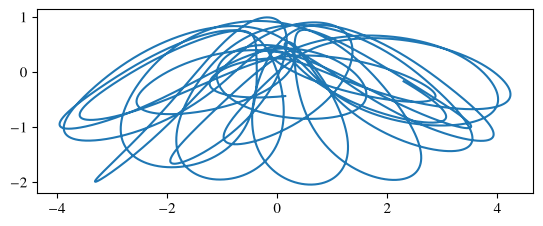

In [ ]:
fig,axis=plt.subplots(1,1)
axis.plot(orbit[:,0],orbit[:,2])
axis.set(aspect="equal");